# Built-up / building classification from LISS-4 (2 swaths, 3 bands) - tiled version

Your AOI is a thin ring, so the notebook **never builds full-size arrays**. It works in 1024 x 1024 tiles and skips
tiles outside the AOI. It also reads the two swaths directly (no separate clip/mosaic files first), which is much faster.

**Steps**
1. Unzip swaths, find Band 2/3/4
2. Tone-match swath 2 to swath 1 (they are different dates) using the overlap
3. **Check footprint-to-image alignment** (a 1-pixel shift ruins pixel-level accuracy for 36 m2 houses) and correct it
4. Rasterize footprints to a coverage raster, split the AOI into spatial blocks: train / validation / test
5. Sample training pixels, build features (bands, NDVI, local contrast, texture, edges)
6. Train a gradient-boosting classifier
7. Predict all tiles, choose the probability threshold on the **validation** blocks (not 0.5)
8. Accuracy assessment on **test** blocks: strict pixel metrics, 1-pixel-tolerant metrics, per-building detection rate
9. Outputs: mosaic, coverage, probability, classification rasters, accuracy table

Run cells top to bottom. Only the CONFIG cell needs editing.

In [1]:
import os, re, glob, zipfile, time, warnings
from types import SimpleNamespace as NS
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from affine import Affine
from rasterio import features
from rasterio.windows import Window
from rasterio.vrt import WarpedVRT
from rasterio.warp import Resampling
from scipy import ndimage as ndi
from scipy.ndimage import uniform_filter, binary_dilation, label, grey_opening, sobel
from shapely import clip_by_rect
from shapely.geometry import mapping, box
from shapely.validation import make_valid
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, cohen_kappa_score
try:
    from tqdm.auto import tqdm
except Exception:
    tqdm = lambda x, **k: x

warnings.filterwarnings("ignore")
print("rasterio", rasterio.__version__, "| geopandas", gpd.__version__)

rasterio 1.4.3 | geopandas 1.1.0


## 1. CONFIG

In [2]:
AOI_SHP   = r"E:\freelancing\Amritpal\layers\aoi_ring_15_200m.shp"
BUILD_SHP = r"E:\freelancing\Amritpal\layers\buildings_ring_15_200m.shp"
ZIPS = {   # name -> zip. First entry has priority where the swaths overlap.
    "swath1_20NOV2025": r"D:\Downloads\RAF20NOV2025046463010400053SSANSTUC00GTDA.zip",
    "swath2_20MAR2026": r"D:\Downloads\RAF20MAR2026048167010400053SSANSTUC00GTDB.zip",
}
OUT_DIR = r"E:\freelancing\Amritpal\output1"

# Optional independent check points (point shapefile, integer field: 1 = building, 0 = not). None to skip.
VALIDATION_POINTS = None
VALIDATION_FIELD  = "class"

# ---- speed / memory ----
TILE = 1024            # tile size in pixels
HALO = 12              # extra pixels read around each tile so filters are correct at tile edges

# ---- preprocessing ----
MATCH_SWATHS   = True  # tone-match swath 2 to swath 1 in the overlap
AUTO_SHIFT     = True  # estimate and correct footprint-to-image misregistration
MAX_SHIFT_PX   = 4     # search +/- this many pixels
SHIFT_MIN_GAIN = 0.03  # apply the shift only if it improves the alignment score by at least this

# ---- labels ----
BUILD_MIN_COVER = 0.50 # pixel is "building" if >= 50% covered by footprints
BG_BUFFER_PX    = 2    # "near-building" zone = within this many pixels of a footprint
HARD_NEG_SHARE  = 0.40 # share of training negatives taken in that near-building zone (hard negatives)

# ---- sampling / split ----
BLOCK_M        = 500   # spatial block size in metres
TEST_FRACTION  = 0.30
VAL_FRACTION   = 0.15
N_TRAIN_POS    = 40000
NEG_RATIO      = 4     # training negatives per positive
N_TEST_PER_CLASS = 5000

# ---- model ----
THRESHOLD = "auto"     # "auto" = pick the probability threshold that maximises F1 on validation blocks, or give a number
SEED = 42

AOI_SHP, BUILD_SHP = AOI_SHP.strip(), BUILD_SHP.strip()
os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)
P = lambda name: os.path.join(OUT_DIR, name)

## 2. Unzip and find the three bands
LISS-4 L2 zips normally contain `BAND2.tif`, `BAND3.tif`, `BAND4.tif`. If your names differ the cell prints what it found and stops.

In [3]:
def find_band(folder, n):
    tifs = [f for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
            if f.lower().endswith((".tif", ".tiff"))]
    pat = re.compile(rf"(^|[^a-z0-9])(band|b)_?0?{n}([^0-9]|$)", re.I)
    hits = [f for f in tifs if pat.search(os.path.splitext(os.path.basename(f))[0])]
    if len(hits) != 1:
        raise RuntimeError(f"Could not identify band {n} in {folder}. TIFs found:\n" + "\n".join(tifs))
    return hits[0]

SWATH_BANDS = {}
for name, zp in ZIPS.items():
    dest = os.path.join(OUT_DIR, "unzipped", name)
    if not glob.glob(os.path.join(dest, "**", "*.tif*"), recursive=True):
        with zipfile.ZipFile(zp) as z:
            z.extractall(dest)
    SWATH_BANDS[name] = [find_band(dest, n) for n in (2, 3, 4)]   # Green, Red, NIR
    with rasterio.open(SWATH_BANDS[name][0]) as s:
        print(f"{name}: {s.width} x {s.height}, {s.dtypes[0]}, res {s.res[0]:.2f} m, EPSG {s.crs.to_epsg()}")

swath1_20NOV2025: 18377 x 16190, uint16, res 5.00 m, EPSG None
swath2_20MAR2026: 18382 x 16342, uint16, res 5.00 m, EPSG None


## 3. Grid, AOI, tiles and swath readers
The working grid is the AOI bounding box, aligned to swath 1's pixel grid. Each swath is exposed as a virtual raster
on that grid, so tiles can be read directly with no intermediate files.

In [4]:
first = next(iter(SWATH_BANDS.values()))[0]
with rasterio.open(first) as s:
    CRS, RES, T0 = s.crs, s.res[0], s.transform
assert CRS.is_projected and T0.e < 0 and abs(T0.b) < 1e-9, "Expected a north-up projected LISS-4 image"

aoi = gpd.read_file(AOI_SHP).to_crs(CRS)
aoi["geometry"] = aoi.geometry.apply(make_valid)
aoi = aoi[~aoi.is_empty]
AOI_UNION = aoi.geometry.union_all() if hasattr(aoi.geometry, "union_all") else aoi.geometry.unary_union
minx, miny, maxx, maxy = aoi.total_bounds
col0 = int(np.floor((minx - T0.c) / RES)); col1 = int(np.ceil((maxx - T0.c) / RES))
row0 = int(np.floor((T0.f - maxy) / RES)); row1 = int(np.ceil((T0.f - miny) / RES))
MTR = Affine(RES, 0, T0.c + col0 * RES, 0, -RES, T0.f - row0 * RES)
W, H = col1 - col0, row1 - row0
print(f"Grid: {W} x {H} px ({W * H / 1e6:.0f} M px) | AOI area {aoi.area.sum() / 1e4:.0f} ha "
      f"= {aoi.area.sum() / RES**2 / 1e6:.2f} M px ({100 * aoi.area.sum() / RES**2 / (W * H):.1f}% of the grid)")

SW = []
for name, paths in SWATH_BANDS.items():
    srcs = [rasterio.open(p) for p in paths]
    vrts = [WarpedVRT(s, crs=CRS, transform=MTR, width=W, height=H, resampling=Resampling.nearest,
                      src_nodata=0, nodata=0) for s in srcs]
    SW.append(NS(name=name, srcs=srcs, vrts=vrts))

def read_sw(k, win):
    return np.stack([v.read(1, window=win).astype("float32") for v in SW[k].vrts])

def make_tile(r0, c0, h, w):
    rh0, ch0 = max(0, r0 - HALO), max(0, c0 - HALO)
    rh1, ch1 = min(H, r0 + h + HALO), min(W, c0 + w + HALO)
    t = NS(r0=r0, c0=c0, h=h, w=w, rh0=rh0, ch0=ch0, hh=rh1 - rh0, ww=ch1 - ch0)
    t.core = (slice(r0 - rh0, r0 - rh0 + h), slice(c0 - ch0, c0 - ch0 + w))
    t.win = Window(ch0, rh0, t.ww, t.hh)
    t.cwin = Window(c0, r0, w, h)
    return t

def aoi_mask(t):
    x0, y1 = MTR * (t.ch0, t.rh0); x1, y0 = MTR * (t.ch0 + t.ww, t.rh0 + t.hh)
    g = clip_by_rect(AOI_UNION, x0, y0, x1, y1)
    if g.is_empty:
        return np.zeros((t.hh, t.ww), bool)
    return features.rasterize([(g, 1)], out_shape=(t.hh, t.ww), transform=MTR * Affine.translation(t.ch0, t.rh0),
                              fill=0, dtype="uint8").astype(bool)

TILES = []
for r0 in range(0, H, TILE):
    for c0 in range(0, W, TILE):
        h, w = min(TILE, H - r0), min(TILE, W - c0)
        x0, y1 = MTR * (c0, r0); x1, y0 = MTR * (c0 + w, r0 + h)
        if AOI_UNION.intersects(box(x0, y0, x1, y1)):
            TILES.append((r0, c0, h, w))
print(f"{len(TILES)} tiles touch the AOI (of {((H + TILE - 1) // TILE) * ((W + TILE - 1) // TILE)})")

TONE = None
def load_imagery(t):
    a = read_sw(0, t.win)
    v1 = (a > 0).all(0)
    sw = v1.astype(np.uint8)
    img = a
    if len(SW) > 1:
        b = read_sw(1, t.win)
        v2 = (b > 0).all(0)
        if TONE is not None:
            for i in range(3):
                b[i][v2] = np.interp(b[i][v2], TONE[i][0], TONE[i][1])
        use2 = v2 & ~v1
        img = np.where(use2[None], b, a)
        sw[use2] = 2
    t.img, t.sw = img.astype("float32"), sw
    t.aoi = aoi_mask(t)
    t.valid = t.aoi & (sw > 0)
    return t

Grid: 10802 x 9261 px (100 M px) | AOI area 2957 ha = 1.18 M px (1.2% of the grid)
22 tiles touch the AOI (of 110)


## 4. Tone-match swath 2 to swath 1
The swaths are four months apart. Quantile mapping on the overlap pixels brings swath 2 closer to swath 1.
Cross-check the printed means. If the overlap is small, matching is skipped.

In [5]:
def fit_tone():
    if len(SW) < 2 or not MATCH_SWATHS:
        return None
    A, B = [], []
    for r0, c0, h, w in TILES:
        t = make_tile(r0, c0, h, w)
        a, b = read_sw(0, t.win)[:, t.core[0], t.core[1]], read_sw(1, t.win)[:, t.core[0], t.core[1]]
        ov = (a > 0).all(0) & (b > 0).all(0)
        idx = np.flatnonzero(ov.ravel())
        if len(idx) == 0:
            continue
        idx = rng.choice(idx, min(len(idx), 30000), replace=False)
        A.append(a.reshape(3, -1)[:, idx]); B.append(b.reshape(3, -1)[:, idx])
    if not A:
        print("No overlap between swaths inside the AOI - tone matching skipped"); return None
    A, B = np.hstack(A), np.hstack(B)
    print(f"Overlap sample: {A.shape[1]:,} pixels")
    if A.shape[1] < 5000:
        print("Overlap too small - tone matching skipped"); return None
    q = np.linspace(0, 100, 101)
    tone = []
    for i in range(3):
        sq = np.percentile(B[i], q); rq = np.percentile(A[i], q)
        sq = sq + np.arange(len(sq)) * 1e-6
        tone.append((sq, rq))
    print("Band means  swath1:", A.mean(1).round(1), "| swath2 before:", B.mean(1).round(1),
          "| swath2 after:", np.array([np.interp(B[i], *tone[i]).mean() for i in range(3)]).round(1))
    return tone

TONE = fit_tone()

Overlap sample: 120,000 pixels
Band means  swath1: [ 97.4  87.3 140.7] | swath2 before: [126.3 110.5 195.1] | swath2 after: [ 96.6  86.7 140.5]


## 5. Footprints and alignment check
At 5 m, a house of 36 m2 is about 1.4 pixels. If the footprint layer is offset from the image by even one pixel,
pixel labels are wrong. For each swath the cell tests shifts of +/- `MAX_SHIFT_PX` pixels and keeps the one where
footprint pixels differ most from their surroundings (brighter and less vegetated).

In [6]:
bld = gpd.read_file(BUILD_SHP).to_crs(CRS)
bld = bld[bld.geometry.notna() & ~bld.is_empty].copy()
bld["geometry"] = bld.geometry.apply(make_valid)
SIDX = bld.sindex
print(f"{len(bld):,} footprints | {bld.area.sum() / 1e4:.1f} ha | median {bld.area.median():.0f} m2 "
      f"| {100 * (bld.area < RES**2 / 2).mean():.0f}% are smaller than half a pixel")

def cov_window(t, shift=(0.0, 0.0), f=4):
    # fraction of each pixel covered by footprints; footprints are moved by `shift` (east, north) metres
    dx, dy = shift
    tr = Affine.translation(-dx, -dy) * MTR * Affine.translation(t.ch0, t.rh0)
    x0, y1 = tr * (0, 0); x1, y0 = tr * (t.ww, t.hh)
    hit = SIDX.query(box(min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1)),
                     predicate="intersects")
    if len(hit) == 0:
        return np.zeros((t.hh, t.ww), np.float32)
    geoms = bld.geometry.iloc[hit]
    fine = features.rasterize([(g, 1) for g in geoms], out_shape=(t.hh * f, t.ww * f),
                              transform=tr * Affine.scale(1 / f), fill=0, dtype="uint8")
    return fine.reshape(t.hh, f, t.ww, f).mean(axis=(1, 3)).astype(np.float32)

SHIFTS = {1: (0.0, 0.0), 2: (0.0, 0.0)}

def pick_tiles(k, n=5):
    cen = bld.geometry.centroid
    cr = ((MTR.f - cen.y.values) / RES).astype(int) // TILE; cc = ((cen.x.values - MTR.c) / RES).astype(int) // TILE
    cnt = pd.Series(list(zip(cr, cc))).value_counts()
    out = []
    for (tr_, tc_), _ in cnt.items():
        if (tr_ * TILE, tc_ * TILE) not in [(a, b) for a, b, _, _ in TILES]:
            continue
        r0, c0 = tr_ * TILE, tc_ * TILE
        t = make_tile(r0, c0, min(TILE, H - r0), min(TILE, W - c0))
        aoi_m = aoi_mask(t)
        v = (read_sw(k, t.win)[0] > 0) & aoi_m
        if aoi_m.sum() > 0 and v.sum() / aoi_m.sum() > 0.4:
            out.append(t)
        if len(out) >= n:
            break
    return out

def estimate_shift(k, tiles):
    M = MAX_SHIFT_PX
    S = np.zeros((2 * M + 1, 2 * M + 1)); used = 0
    for t in tiles:
        a = read_sw(k, t.win); v = (a > 0).all(0)
        ok_all = v & aoi_mask(t)
        b = a.mean(0); nd = (a[2] - a[1]) / (a[2] + a[1] + 1e-6)
        z = lambda x: (x - x[v].mean()) / (x[v].std() + 1e-6)
        Pm = z(b - uniform_filter(b, 21)) - z(nd - uniform_filter(nd, 21))
        cov0 = cov_window(t, f=1) > 0
        inner = (slice(M, -M), slice(M, -M))
        ok = ok_all[inner]; pm = Pm[inner]
        if cov0[inner].sum() < 50:
            continue
        for iy, dy in enumerate(range(-M, M + 1)):
            for ix, dx in enumerate(range(-M, M + 1)):
                m = np.roll(cov0, (dy, dx), (0, 1))[inner]
                mk, bk = m & ok, (~m) & ok
                if mk.sum() >= 30 and bk.sum() >= 30:
                    S[iy, ix] += pm[mk].mean() - pm[bk].mean()
        used += 1
    return S / max(used, 1), used

if AUTO_SHIFT:
    for k in range(len(SW)):
        tiles = pick_tiles(k)
        if not tiles:
            print(f"swath {k + 1}: no suitable tiles for the alignment check"); continue
        S, used = estimate_shift(k, tiles)
        M = MAX_SHIFT_PX
        iy, ix = np.unravel_index(np.argmax(S), S.shape)
        s0 = S[M, M]; best = S[iy, ix]
        dy_px, dx_px = iy - M, ix - M
        print(f"\nswath {k + 1} ({SW[k].name}): alignment score at 0 shift = {s0:.3f}, best = {best:.3f} at "
              f"dx={dx_px:+d}, dy={dy_px:+d} px  ({used} tiles)")
        print(pd.DataFrame(S, index=[f"dy{d:+d}" for d in range(-M, M + 1)],
                           columns=[f"dx{d:+d}" for d in range(-M, M + 1)]).round(2).to_string())
        if (dx_px, dy_px) != (0, 0) and best - s0 >= SHIFT_MIN_GAIN:
            SHIFTS[k + 1] = (dx_px * RES, -dy_px * RES)
            print(f"-> footprints shifted by {SHIFTS[k + 1][0]:+.1f} m east, {SHIFTS[k + 1][1]:+.1f} m north for swath {k + 1}")
        else:
            print("-> no significant shift; footprints kept as they are")
print("\nShifts in use (east, north metres):", SHIFTS)

25,256 footprints | 155.7 ha | median 36 m2 | 9% are smaller than half a pixel

swath 1 (swath1_20NOV2025): alignment score at 0 shift = 1.017, best = 1.020 at dx=-1, dy=+0 px  (5 tiles)
      dx-4  dx-3  dx-2  dx-1  dx+0  dx+1  dx+2  dx+3  dx+4
dy-4  0.03  0.03  0.05  0.10  0.17  0.21  0.19  0.14  0.09
dy-3  0.06  0.06  0.07  0.15  0.24  0.28  0.23  0.17  0.12
dy-2  0.11  0.15  0.22  0.37  0.48  0.44  0.32  0.22  0.14
dy-1  0.18  0.29  0.49  0.76  0.84  0.65  0.42  0.28  0.17
dy+0  0.22  0.41  0.72  1.02  1.02  0.74  0.47  0.31  0.19
dy+1  0.22  0.43  0.73  0.94  0.88  0.65  0.45  0.31  0.20
dy+2  0.20  0.37  0.57  0.67  0.62  0.50  0.39  0.29  0.20
dy+3  0.17  0.29  0.39  0.44  0.41  0.37  0.31  0.25  0.18
dy+4  0.13  0.21  0.26  0.28  0.28  0.26  0.22  0.18  0.15
-> no significant shift; footprints kept as they are

swath 2 (swath2_20MAR2026): alignment score at 0 shift = 1.085, best = 1.234 at dx=-1, dy=+0 px  (5 tiles)
      dx-4  dx-3  dx-2  dx-1  dx+0  dx+1  dx+2  dx+3  dx+4
dy-

## 6. Pass 1: footprint coverage raster and block statistics
`footprint_coverage.tif` stores the covered percentage (0-100) of each pixel. The AOI is cut into square blocks and
the building counts per block are collected, so the train / validation / test split can be made without any image processing.

In [7]:
blk = max(1, int(round(BLOCK_M / RES)))
ncb = W // blk + 1
NB = (H // blk + 1) * ncb

def block_ids(t):
    rows = t.r0 + np.arange(t.h); cols = t.c0 + np.arange(t.w)
    return ((rows // blk)[:, None] * ncb + (cols // blk)[None, :]).astype(np.int32)

def tile_cov(t):
    sw = np.zeros((t.hh, t.ww), np.uint8)
    for k in range(len(SW)):
        sw[(read_sw(k, t.win)[0] > 0) & (sw == 0)] = k + 1
    if len(SW) == 1 or SHIFTS[2] == SHIFTS[1] or not (sw == 2).any():
        return cov_window(t, SHIFTS[1])
    if not (sw == 1).any():
        return cov_window(t, SHIFTS[2])
    return np.where(sw == 2, cov_window(t, SHIFTS[2]), cov_window(t, SHIFTS[1]))

cnt = {k: np.zeros(NB, np.int64) for k in ("valid", "ref", "neg", "nn")}
prof_u8 = dict(driver="GTiff", height=H, width=W, count=1, dtype="uint8", crs=CRS, transform=MTR,
               tiled=True, blockxsize=512, blockysize=512, compress="deflate", nodata=255)
t_start = time.time()
with rasterio.open(P("footprint_coverage.tif"), "w", **prof_u8) as dst:
    for r0, c0, h, w in tqdm(TILES, desc="pass 1"):
        t = make_tile(r0, c0, h, w)
        t.aoi = aoi_mask(t)
        cov = tile_cov(t)
        dst.write(np.round(cov[t.core] * 100).astype(np.uint8), 1, window=t.cwin)
        near = binary_dilation(cov > 0, iterations=BG_BUFFER_PX)[t.core]
        a = t.aoi[t.core]; cc = cov[t.core]; bid = block_ids(t)
        for key, m in (("valid", a), ("ref", a & (cc >= BUILD_MIN_COVER)), ("neg", a & ~near),
                       ("nn", a & near & (cc == 0))):
            cnt[key] += np.bincount(bid[m], minlength=NB)
print(f"pass 1 done in {time.time() - t_start:.0f}s")
n_valid_blk, n_ref_blk, n_neg_blk, n_nn_blk = cnt["valid"], cnt["ref"], cnt["neg"], cnt["nn"]
print(f"AOI pixels {n_valid_blk.sum():,} | reference building pixels {n_ref_blk.sum():,} "
      f"({100 * n_ref_blk.sum() / n_valid_blk.sum():.2f}%)")

pass 1:   0%|          | 0/22 [00:00<?, ?it/s]

pass 1 done in 16s
AOI pixels 1,183,025 | reference building pixels 60,198 (5.09%)


## 7. Spatial split: train / validation / test blocks
Whole blocks go to one set only. Validation blocks pick the threshold. Test blocks give the final accuracy
and are never used for any decision.

In [8]:
cand = np.flatnonzero(n_valid_blk > 0)
tot_valid, tot_ref = n_valid_blk.sum(), n_ref_blk.sum()

def fill(order, frac):
    take, acc = [], 0
    for b in order:
        take.append(b); acc += n_valid_blk[b]
        if acc >= frac * tot_valid:
            break
    return np.array(take)

BLK_SET = None
for attempt in range(2000):
    test = fill(rng.permutation(cand), TEST_FRACTION)
    val = fill(rng.permutation(np.setdiff1d(cand, test)), VAL_FRACTION)
    te, va = n_ref_blk[test].sum(), n_ref_blk[val].sum()
    tr = tot_ref - te - va
    if te >= max(300, 0.15 * tot_ref) and va >= max(300, 0.07 * tot_ref) and tr >= 0.3 * tot_ref:
        BLK_SET = np.zeros(NB, np.uint8)          # 0 = unused, 1 = train, 2 = validation, 3 = test
        BLK_SET[cand] = 1; BLK_SET[val] = 2; BLK_SET[test] = 3
        break
if BLK_SET is None:
    raise RuntimeError("Could not split the blocks with enough buildings in each part. Reduce BLOCK_M.")
for s, nm in ((1, "train"), (2, "validation"), (3, "test")):
    m = BLK_SET == s
    print(f"{nm:10s}: {m.sum():4d} blocks | {n_valid_blk[m].sum():>9,} px | {n_ref_blk[m].sum():>7,} building px")

train     :  180 blocks |   647,244 px |  37,105 building px
validation:   55 blocks |   178,331 px |   7,609 building px
test      :  101 blocks |   357,450 px |  15,484 building px


## 8. Features
Besides the bands and NDVI, the features describe how a pixel differs from its surroundings
(houses are compact bright objects with edges, in a smoother field/soil background): local contrast, local standard deviation,
a white top-hat, edge strength, and the swath id (so the model can handle the two dates).

In [9]:
def local_std(a, k):
    m = uniform_filter(a, k); m2 = uniform_filter(a * a, k)
    return np.sqrt(np.maximum(m2 - m * m, 0))

FEAT = ["green", "red", "nir", "ndvi", "brightness", "bright_contrast21", "nir_contrast21", "ndvi_contrast21",
        "bright_std3", "bright_std7", "nir_std5", "red_std5", "ndvi_mean7", "bright_mean7", "tophat7", "edge", "swath"]

def make_features(t):
    g, r, n = t.img
    b = (g + r + n) / 3
    nd = (n - r) / (n + r + 1e-6)
    sb = uniform_filter(b, 3)
    edge = np.hypot(sobel(sb, 0), sobel(sb, 1))
    F = np.stack([g, r, n, nd, b,
                  b - uniform_filter(b, 21), n - uniform_filter(n, 21), nd - uniform_filter(nd, 21),
                  local_std(b, 3), local_std(b, 7), local_std(n, 5), local_std(r, 5),
                  uniform_filter(nd, 7), uniform_filter(b, 7),
                  b - grey_opening(b, size=(7, 7)), edge, t.sw.astype(np.float32)]).astype(np.float32)
    return F

# pool sizes -> sampling probabilities
ps = lambda arr, s: arr[BLK_SET == s].sum()
pool = dict(tr_pos=ps(n_ref_blk, 1), tr_neg=ps(n_neg_blk, 1), tr_nn=ps(n_nn_blk, 1),
            te_pos=ps(n_ref_blk, 3), te_neg=ps(n_neg_blk, 3) + ps(n_nn_blk, 3))
n_tr_pos = min(N_TRAIN_POS, pool["tr_pos"])
n_neg_tr = n_tr_pos * NEG_RATIO
prob_sel = dict(tr_pos=n_tr_pos / pool["tr_pos"],
                tr_neg=min(1, n_neg_tr * (1 - HARD_NEG_SHARE) / max(pool["tr_neg"], 1)),
                tr_nn=min(1, n_neg_tr * HARD_NEG_SHARE / max(pool["tr_nn"], 1)),
                te_pos=min(1, N_TEST_PER_CLASS / pool["te_pos"]), te_neg=min(1, N_TEST_PER_CLASS / pool["te_neg"]))
print({k: f"{v:,}" for k, v in pool.items()})

cov_ds = rasterio.open(P("footprint_coverage.tif"))
samples = []   # (row, col, label, set, features)
t_start = time.time()
for r0, c0, h, w in tqdm(TILES, desc="pass 2 (sampling)"):
    t = load_imagery(make_tile(r0, c0, h, w))
    cov = cov_ds.read(1, window=t.win).astype(np.float32) / 100.0
    near = binary_dilation(cov > 0, iterations=BG_BUFFER_PX)[t.core]
    cc = cov[t.core]; v = t.valid[t.core]; sets = BLK_SET[block_ids(t)]
    pos = v & (cc >= BUILD_MIN_COVER)
    far = v & ~near                    # far from any footprint
    nn = v & near & (cc == 0)          # right next to a footprint, but not touched by it
    none = v & (cc == 0)               # not touched by any footprint
    u = rng.random((h, w))
    sel = {"tr_pos": pos & (sets == 1) & (u < prob_sel["tr_pos"]),
           "tr_neg": far & (sets == 1) & (u < prob_sel["tr_neg"]),
           "tr_nn":  nn & (sets == 1) & (u < prob_sel["tr_nn"]),
           "te_pos": pos & (sets == 3) & (u < prob_sel["te_pos"]),
           "te_neg": none & (sets == 3) & (u < prob_sel["te_neg"])}
    if not any(m.any() for m in sel.values()):
        continue
    F = make_features(t)
    for key, m in sel.items():
        rr, cc_ = np.nonzero(m)
        if len(rr) == 0:
            continue
        X = F[:, rr + t.core[0].start, cc_ + t.core[1].start].T
        samples.append((rr + r0, cc_ + c0, np.full(len(rr), key.endswith("pos"), int),
                        np.full(len(rr), 1 if key.startswith("tr") else 3), X))
print(f"pass 2 done in {time.time() - t_start:.0f}s")

S_row = np.concatenate([s[0] for s in samples]); S_col = np.concatenate([s[1] for s in samples])
S_y = np.concatenate([s[2] for s in samples]); S_set = np.concatenate([s[3] for s in samples])
S_X = np.vstack([s[4] for s in samples])
Xtr, ytr = S_X[S_set == 1], S_y[S_set == 1]
Xte, yte = S_X[S_set == 3], S_y[S_set == 3]
print(f"train: {len(ytr):,} samples ({ytr.sum():,} building) | test: {len(yte):,} ({yte.sum():,} building)")
xs, ys = rasterio.transform.xy(MTR, S_row, S_col)
gpd.GeoDataFrame({"cls": S_y, "set": np.where(S_set == 1, "train", "test")},
                 geometry=gpd.points_from_xy(xs, ys), crs=CRS).to_file(P("sample_points.gpkg"), driver="GPKG")

{'tr_pos': '37,105', 'tr_neg': '488,121', 'tr_nn': '90,929', 'te_pos': '15,484', 'te_neg': '327,490'}


pass 2 (sampling):   0%|          | 0/22 [00:00<?, ?it/s]

pass 2 done in 18s
train: 185,433 samples (37,105 building) | test: 9,955 (4,997 building)


**Note on the "non-building" samples:** they are pixels not touched by any footprint. `HARD_NEG_SHARE` of them are taken
right beside buildings, so the model learns that the surroundings of a house are not building (without this it paints a halo around every house).
Pixels only partly covered by a footprint (0 < cover < 50%) are left out of training because they are ambiguous.
If the footprint layer misses some buildings, those buildings are taught as non-building, which lowers accuracy
and cannot be fixed by code. Look at the final map next to the imagery to judge how complete the footprints are.

## 9. Train the classifier

In [10]:
t_start = time.time()
model = HistGradientBoostingClassifier(max_iter=250, learning_rate=0.08, max_leaf_nodes=63,
                                       l2_regularization=1.0, random_state=SEED)
model.fit(Xtr, ytr)
print(f"trained in {time.time() - t_start:.0f}s")

pi = permutation_importance(model, Xte, yte, n_repeats=3, random_state=SEED, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEAT).sort_values(ascending=False)
imp.to_csv(P("feature_importance.csv"))
print("\nPermutation importance (drop in ROC-AUC on test samples):")
print(imp.round(4).to_string())

trained in 13s

Permutation importance (drop in ROC-AUC on test samples):
ndvi                 0.0970
green                0.0657
red_std5             0.0344
bright_std7          0.0332
swath                0.0316
tophat7              0.0258
red                  0.0181
bright_std3          0.0167
nir_std5             0.0162
nir                  0.0067
ndvi_contrast21      0.0065
edge                 0.0064
bright_mean7         0.0048
ndvi_mean7           0.0039
bright_contrast21    0.0036
nir_contrast21       0.0015
brightness           0.0010


## 10. Pass 3: predict every tile
Writes `building_probability.tif` and `liss4_mosaic_aoi.tif` (tone-matched, AOI only), and collects probability histograms
of validation and test pixels for threshold selection.

In [11]:
EDGES = np.linspace(0, 1, 1001)
HIST = {(s, c): np.zeros(len(EDGES) - 1, np.int64) for s in (2, 3) for c in (0, 1)}

prof_f = dict(prof_u8, dtype="float32", nodata=-1.0, predictor=3)
prof_m = dict(prof_u8, count=3, dtype="uint16", nodata=0)
t_start = time.time()
with rasterio.open(P("building_probability.tif"), "w", **prof_f) as dp, \
     rasterio.open(P("liss4_mosaic_aoi.tif"), "w", **prof_m) as dm:
    for r0, c0, h, w in tqdm(TILES, desc="pass 3 (predict)"):
        t = load_imagery(make_tile(r0, c0, h, w))
        v = t.valid[t.core]
        prob = np.full((h, w), -1, np.float32)
        if v.any():
            F = make_features(t)
            Fc = F[:, t.core[0], t.core[1]]
            prob[v] = model.predict_proba(Fc[:, v].T)[:, 1]
        dp.write(prob, 1, window=t.cwin)
        dm.write(np.clip(t.img[:, t.core[0], t.core[1]] * v[None], 0, 65535).astype(np.uint16), window=t.cwin)
        cov = cov_ds.read(1, window=t.cwin).astype(np.float32) / 100.0
        ref = cov >= BUILD_MIN_COVER; sets = BLK_SET[block_ids(t)]
        for s in (2, 3):
            m = v & (sets == s)
            for c, mm in ((1, m & ref), (0, m & ~ref)):
                HIST[(s, c)] += np.histogram(prob[mm], bins=EDGES)[0]
print(f"pass 3 done in {time.time() - t_start:.0f}s")

pass 3 (predict):   0%|          | 0/22 [00:00<?, ?it/s]

pass 3 done in 25s


## 11. Choose the probability threshold on the validation blocks
The model was trained on 1 building : 4 non-building, but real prevalence is about 1 : 19, so 0.5 gives far too many false positives.
The threshold with the best F1 on the **validation** blocks is used (the test blocks are not touched here).

Threshold used: 0.405  (validation: precision 0.289, recall 0.452, F1 0.352)
For comparison at 0.5   (validation: precision 0.344, recall 0.323, F1 0.333)


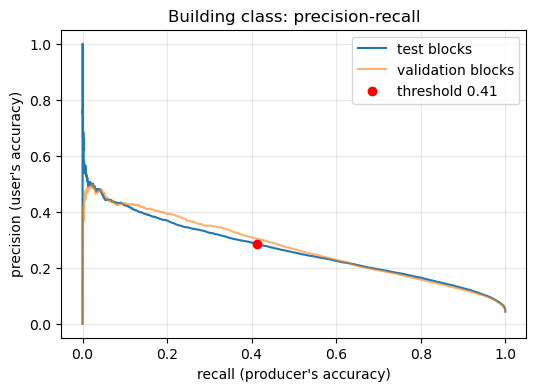

In [12]:
def curve(s):
    pos, neg = HIST[(s, 1)], HIST[(s, 0)]
    tp = np.cumsum(pos[::-1])[::-1]; fp = np.cumsum(neg[::-1])[::-1]
    fn = pos.sum() - tp
    prec = tp / np.maximum(tp + fp, 1); rec = tp / max(pos.sum(), 1)
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    return EDGES[:-1], prec, rec, f1

th, pv, rv, fv = curve(2)
if THRESHOLD == "auto":
    THR = float(th[np.argmax(fv)])
else:
    THR = float(THRESHOLD)
k = np.argmin(np.abs(th - THR))
print(f"Threshold used: {THR:.3f}  (validation: precision {pv[k]:.3f}, recall {rv[k]:.3f}, F1 {fv[k]:.3f})")
k5 = np.argmin(np.abs(th - 0.5))
print(f"For comparison at 0.5   (validation: precision {pv[k5]:.3f}, recall {rv[k5]:.3f}, F1 {fv[k5]:.3f})")

tt, pt, rt, ft = curve(3)
plt.figure(figsize=(6, 4))
plt.plot(rt, pt, label="test blocks"); plt.plot(rv, pv, label="validation blocks", alpha=.6)
plt.scatter([rt[np.argmin(np.abs(tt - THR))]], [pt[np.argmin(np.abs(tt - THR))]], c="r", zorder=3, label=f"threshold {THR:.2f}")
plt.xlabel("recall (producer's accuracy)"); plt.ylabel("precision (user's accuracy)")
plt.title("Building class: precision-recall"); plt.legend(); plt.grid(alpha=.3); plt.show()

## 12. Pass 4: classification raster and test-block assessment
Counted on all pixels of the test blocks:
- **strict**: pixel vs footprint-derived reference
- **mixed pixels excluded**: ignores pixels that are only partly covered by a footprint (0 < cover < 50%)
- **1-pixel tolerant**: a predicted pixel is correct if a reference building is within 1 pixel, a reference pixel is found if a predicted pixel is within 1 pixel (forgives small misregistration)
- **per-building detection**: share of reference building objects (touching footprint pixels) that contain, or touch, at least one predicted pixel, by size

In [13]:
C = dict(tp=0, fp=0, fn=0, tn=0, tp_x=0, fp_x=0, fn_x=0, tn_x=0, rel_prec_num=0, rel_prec_den=0, rel_rec_num=0, rel_rec_den=0)
OBJ_BINS = [2, 4, 9]
obj_tot = np.zeros(4, np.int64); obj_hit = np.zeros(4, np.int64)
S8 = np.ones((3, 3), bool)
prof_c = dict(prof_u8)
prob_ds = rasterio.open(P("building_probability.tif"))
t_start = time.time()
with rasterio.open(P("classification.tif"), "w", **prof_c) as dc:
    for r0, c0, h, w in tqdm(TILES, desc="pass 4"):
        t = make_tile(r0, c0, h, w)
        ph = prob_ds.read(1, window=t.win); ch = cov_ds.read(1, window=t.win).astype(np.float32) / 100.0
        pred_h = ph >= THR; ref_h = ch >= BUILD_MIN_COVER
        pc = ph[t.core]; valid = pc >= 0
        pred = pred_h[t.core]; ref = ref_h[t.core]; cov = ch[t.core]
        dc.write(np.where(valid, pred, 255).astype(np.uint8), 1, window=t.cwin)
        test = valid & (BLK_SET[block_ids(t)] == 3)
        if not test.any():
            continue
        C["tp"] += int((pred & ref & test).sum()); C["fp"] += int((pred & ~ref & test).sum())
        C["fn"] += int((~pred & ref & test).sum()); C["tn"] += int((~pred & ~ref & test).sum())
        keep = test & ~((cov > 0) & (cov < BUILD_MIN_COVER))
        C["tp_x"] += int((pred & ref & keep).sum()); C["fp_x"] += int((pred & ~ref & keep).sum())
        C["fn_x"] += int((~pred & ref & keep).sum()); C["tn_x"] += int((~pred & ~ref & keep).sum())
        pred_d = binary_dilation(pred_h, S8)[t.core]; ref_d = binary_dilation(ref_h, S8)[t.core]
        C["rel_prec_num"] += int((pred & ref_d & test).sum()); C["rel_prec_den"] += int((pred & test).sum())
        C["rel_rec_num"] += int((ref & pred_d & test).sum()); C["rel_rec_den"] += int((ref & test).sum())
        lab, nl = label(cov > 0, structure=S8)
        if nl:
            idx = np.arange(1, nl + 1)
            in_test = ndi.maximum(test.astype(np.uint8), lab, idx) > 0
            hit = ndi.maximum(pred_d.astype(np.uint8), lab, idx) > 0
            area = np.bincount(lab.ravel())[1:]
            cls_ = np.digitize(area, OBJ_BINS)
            for c_ in range(4):
                m = in_test & (cls_ == c_)
                obj_tot[c_] += m.sum(); obj_hit[c_] += (m & hit).sum()
print(f"pass 4 done in {time.time() - t_start:.0f}s")

pass 4:   0%|          | 0/22 [00:00<?, ?it/s]

pass 4 done in 6s


## 13. Accuracy report

In [14]:
def metrics(tp, fp, fn, tn, title):
    n = tp + fp + fn + tn
    oa = (tp + tn) / n
    pe = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n**2
    kappa = (oa - pe) / (1 - pe) if pe < 1 else np.nan
    pa_b, ua_b = tp / max(tp + fn, 1), tp / max(tp + fp, 1)
    pa_n, ua_n = tn / max(tn + fp, 1), tn / max(tn + fn, 1)
    f1 = 2 * tp / max(2 * tp + fp + fn, 1); iou = tp / max(tp + fp + fn, 1)
    print("=" * 70); print(title); print("=" * 70)
    print(pd.DataFrame([[tn, fp], [fn, tp]], index=["ref non-building", "ref building"],
                       columns=["pred non-building", "pred building"]).to_string())
    print(f"\nN = {n:,}  Overall accuracy = {oa:.3f}  Kappa = {kappa:.3f}")
    print(f"Building     : producer's = {pa_b:.3f}  user's = {ua_b:.3f}  F1 = {f1:.3f}  IoU = {iou:.3f}")
    print(f"Non-building : producer's = {pa_n:.3f}  user's = {ua_n:.3f}\n")
    return dict(set=title, N=n, OA=oa, kappa=kappa, PA_building=pa_b, UA_building=ua_b, PA_nonbuilding=pa_n,
                UA_nonbuilding=ua_n, F1_building=f1, IoU_building=iou, TN=tn, FP=fp, FN=fn, TP=tp)

results = []
# A. balanced sample points in test blocks
pa = (model.predict_proba(Xte)[:, 1] >= THR)
tn, fp, fn, tp = confusion_matrix(yte, pa.astype(int), labels=[0, 1]).ravel()
results.append(metrics(tp, fp, fn, tn, "A. Balanced sample points in test blocks"))
# B. wall-to-wall
results.append(metrics(C["tp"], C["fp"], C["fn"], C["tn"], "B. Wall-to-wall, all pixels in test blocks (strict)"))
results.append(metrics(C["tp_x"], C["fp_x"], C["fn_x"], C["tn_x"], "B2. Wall-to-wall, mixed pixels excluded"))

rp = C["rel_prec_num"] / max(C["rel_prec_den"], 1); rr = C["rel_rec_num"] / max(C["rel_rec_den"], 1)
print("=" * 70); print("C. 1-pixel tolerant (test blocks)"); print("=" * 70)
print(f"user's accuracy (precision) = {rp:.3f} | producer's accuracy (recall) = {rr:.3f} | F1 = {2 * rp * rr / max(rp + rr, 1e-9):.3f}\n")
results.append(dict(set="C. 1-pixel tolerant", UA_building=rp, PA_building=rr, F1_building=2 * rp * rr / max(rp + rr, 1e-9)))

print("=" * 70); print("D. Per-building detection in test blocks (object = group of touching footprint pixels)"); print("=" * 70)
labels_ = ["1 px", "2-3 px", "4-8 px", ">=9 px"]   # pixel = RES x RES metres
det = pd.DataFrame({"objects": obj_tot, "detected": obj_hit, "detection rate": (obj_hit / np.maximum(obj_tot, 1)).round(3)}, index=labels_)
print(det.to_string()); print(f"\nOverall detection rate: {obj_hit.sum() / max(obj_tot.sum(), 1):.3f}\n")
results.append(dict(set="D. Per-building detection (all sizes)", PA_building=obj_hit.sum() / max(obj_tot.sum(), 1), N=int(obj_tot.sum())))

# E. optional independent points
if VALIDATION_POINTS:
    vp = gpd.read_file(VALIDATION_POINTS).to_crs(CRS)
    with rasterio.open(P("classification.tif")) as cd:
        pv_ = np.array([v[0] for v in cd.sample(zip(vp.geometry.x, vp.geometry.y))])
    ok = pv_ != 255
    yv = vp[VALIDATION_FIELD].values[ok].astype(int); pp = (pv_[ok] == 1).astype(int)
    tn, fp, fn, tp = confusion_matrix(yv, pp, labels=[0, 1]).ravel()
    results.append(metrics(tp, fp, fn, tn, f"E. Independent points ({ok.sum()} used)"))

pd.DataFrame(results).to_csv(P("accuracy_assessment.csv"), index=False)
print("Saved accuracy_assessment.csv. Threshold used:", round(THR, 3))

A. Balanced sample points in test blocks
                  pred non-building  pred building
ref non-building               4780            178
ref building                   2916           2081

N = 9,955  Overall accuracy = 0.689  Kappa = 0.380
Building     : producer's = 0.416  user's = 0.921  F1 = 0.574  IoU = 0.402
Non-building : producer's = 0.964  user's = 0.621

B. Wall-to-wall, all pixels in test blocks (strict)
                  pred non-building  pred building
ref non-building             325886          16080
ref building                   9093           6391

N = 357,450  Overall accuracy = 0.930  Kappa = 0.301
Building     : producer's = 0.413  user's = 0.284  F1 = 0.337  IoU = 0.202
Non-building : producer's = 0.953  user's = 0.973

B2. Wall-to-wall, mixed pixels excluded
                  pred non-building  pred building
ref non-building             315280          12210
ref building                   9093           6391

N = 342,974  Overall accuracy = 0.938  Kappa = 0.

## 14. Look at the result in the tile with the most buildings

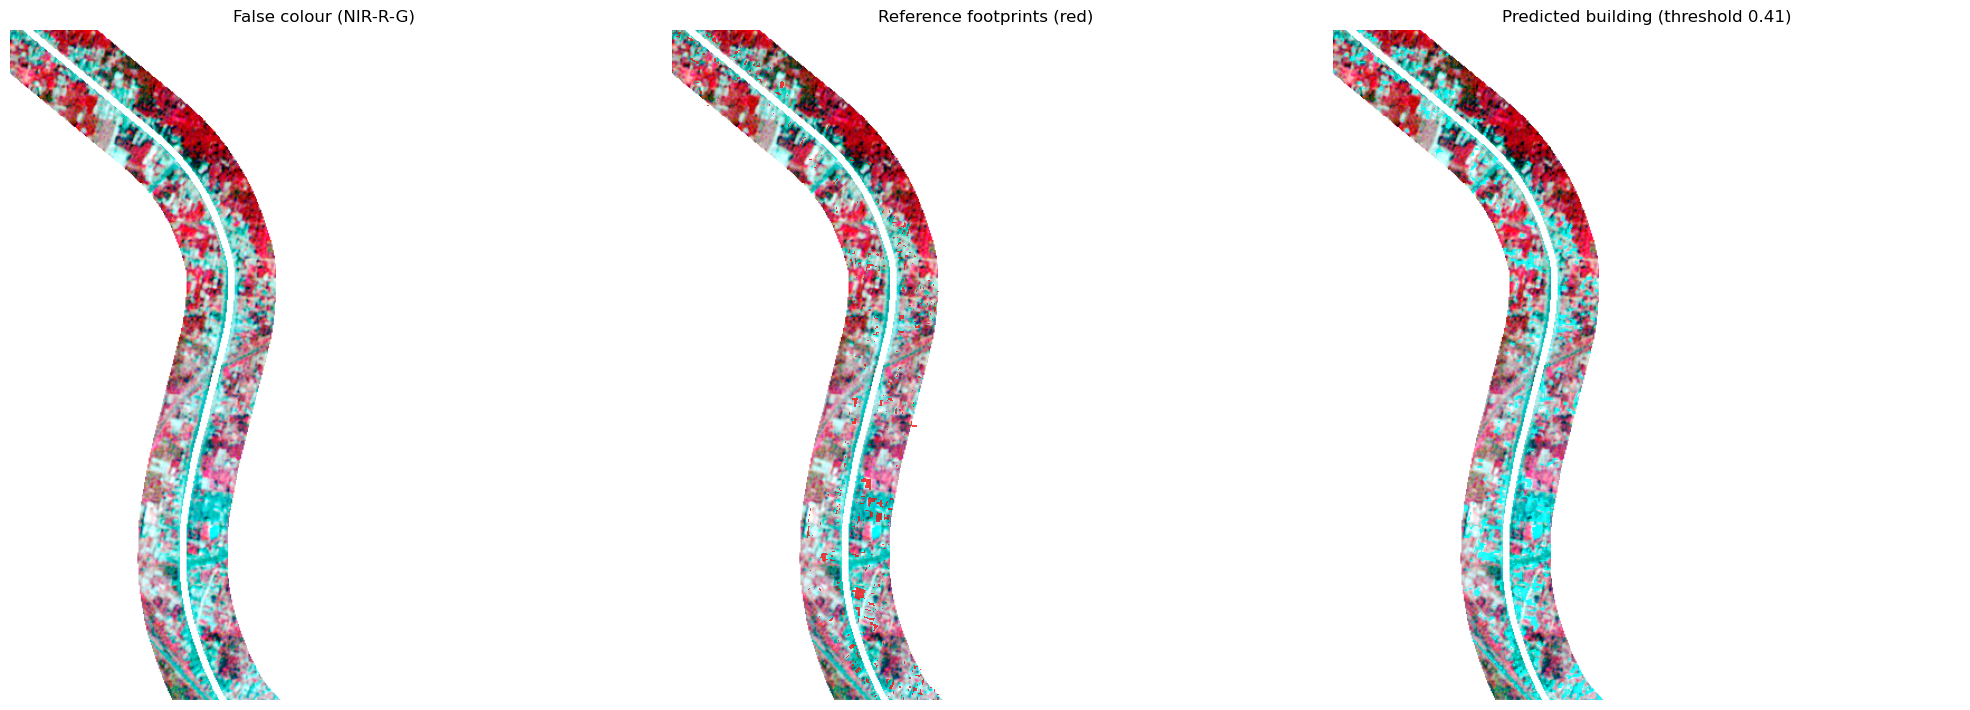

Outputs in: E:\freelancing\Amritpal\output1
['accuracy_assessment.csv', 'building_probability.tif', 'classification.tif', 'feature_importance.csv', 'footprint_coverage.tif', 'liss4_mosaic_aoi.tif', 'result_overview.png', 'sample_points.gpkg', 'unzipped']


In [15]:
# choose the tile with most reference buildings, show a 600 x 600 px crop
best, bn = None, -1
for r0, c0, h, w in TILES:
    t = make_tile(r0, c0, h, w)
    n = int((cov_ds.read(1, window=t.cwin) >= BUILD_MIN_COVER * 100).sum())
    if n > bn:
        best, bn = t, n
t = best
cr0, cc0 = t.r0 + max(0, (t.h - 600) // 2), t.c0 + max(0, (t.w - 600) // 2)
win = Window(cc0, cr0, min(600, t.w), min(600, t.h))
with rasterio.open(P("liss4_mosaic_aoi.tif")) as d:
    m = d.read(window=win).astype(np.float32)
cl = rasterio.open(P("classification.tif")).read(1, window=win)
cv = cov_ds.read(1, window=win) / 100.0
vv = (m > 0).all(0)
def st(a):
    lo, hi = np.percentile(a[vv], (2, 98)) if vv.any() else (0, 1)
    return np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)
fcc = np.dstack([st(m[2]), st(m[1]), st(m[0])]); fcc[~vv] = 1
fig, ax = plt.subplots(1, 3, figsize=(20, 7), sharex=True, sharey=True)
ax[0].imshow(fcc); ax[0].set_title("False colour (NIR-R-G)")
ax[1].imshow(fcc); ax[1].imshow(np.where(cv >= BUILD_MIN_COVER, 1.0, np.nan), cmap="autumn", alpha=.75); ax[1].set_title("Reference footprints (red)")
ax[2].imshow(fcc); ax[2].imshow(np.where(cl == 1, 1.0, np.nan), cmap="cool", alpha=.75); ax[2].set_title(f"Predicted building (threshold {THR:.2f})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(P("result_overview.png"), dpi=130); plt.show()
print("Outputs in:", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))